In [90]:
%matplotlib inline

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
import rasterio
with rasterio.open('../dat/tif/tsa01/projected_fire_2015.tif') as src:
    x = src.read()
    print(x[0].sum())

1674


In [3]:
import pandas as pd
df1 = pd.read_csv('../dat/targets_old20180706.csv')
df2 = pd.read_csv('../dat/targets.csv')


In [4]:
df1.head()

,tsa,period,vcut,abrn,cflw_acut_e,cgen_vcut_e,cgen_abrn_e
0,tsa01,1,4538783,7721,0.2,0.01,0.01
1,tsa01,2,4538783,7721,0.2,0.01,0.01
2,tsa01,3,4538783,7721,0.2,0.01,0.01
3,tsa01,4,4538783,7721,0.2,0.01,0.01
4,tsa02,1,7176070,2786,0.2,0.01,0.01


In [87]:
df1.index

RangeIndex(start=0, stop=152, step=1)

In [89]:
if 'tsa01' in df1.set_index('tsa').index: print('foo')

In [75]:
df2 = df2.reset_index()

In [76]:
df2['dvcut'] = (df2.vcut - df1.vcut)
df2['rdvcut'] = df2.dvcut / df1.vcut

In [78]:
df2['dabrn'] = (df2.abrn - df1.abrn)
df2['rdabrn'] = df2.dabrn / df1.abrn

In [30]:
df2.dvcut.sum() / df2.vcut.sum()

0.11670611634544543

In [ ]:
df2.dvcut.sum()

In [79]:
df2.dabrn.sum() / df2.abrn.sum()

-0.085154057291082483

In [80]:
df2 = df2.set_index(['tsa', 'period'])

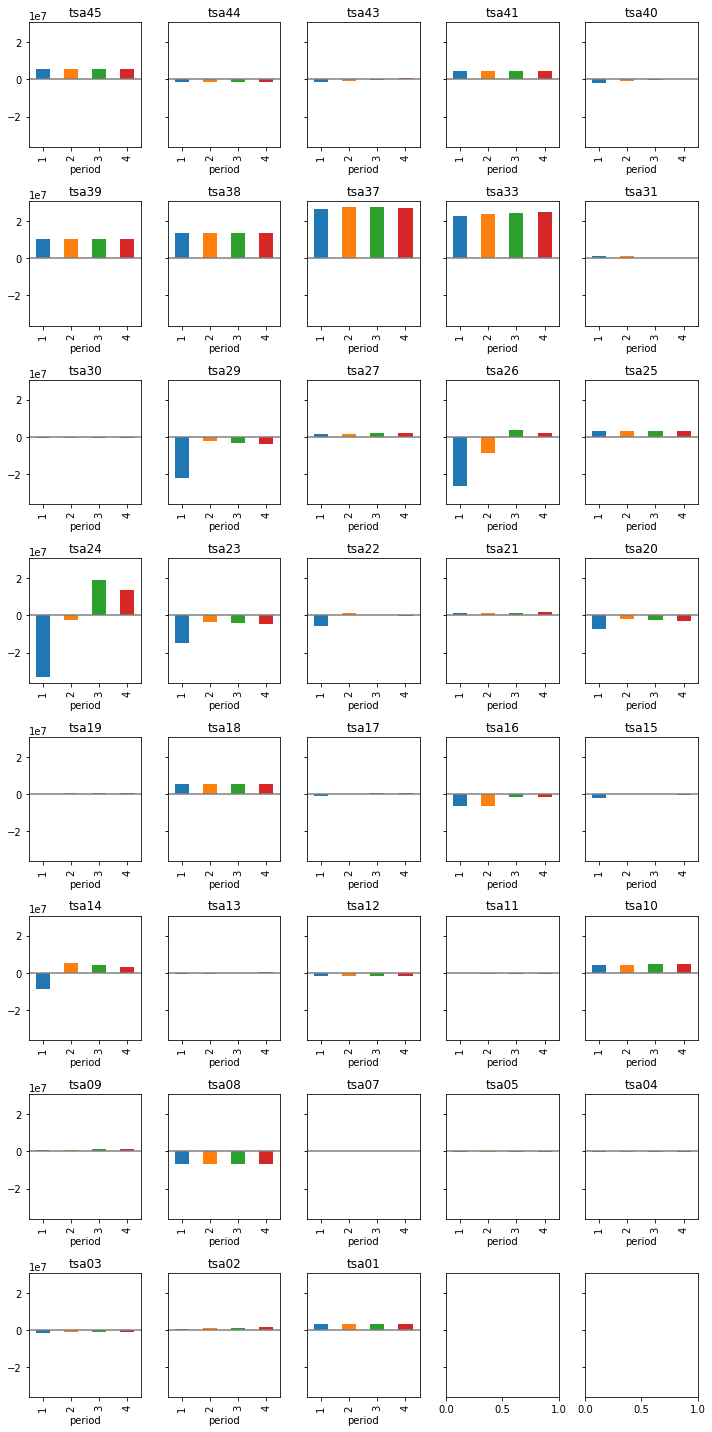

In [102]:
basenames = list(df2.index.get_level_values(level=0).unique())
fig, ax = plt.subplots(8, 5, sharey=True, figsize=(10, 20))
#plt.scatter(df2.index, df2.dvcut)
for i in range(8):
    for j in range(5):
        bn = basenames.pop() if basenames else None
        if not bn: continue
        df2.loc[bn].dvcut.plot(ax=ax[i][j], kind='bar')
        ax[i][j].axhline(color='gray')
        ax[i][j].set_title(bn)
#plt.ylim([-1.0, 10.0])
#plt.title('vcut (relative change in target)')
plt.tight_layout()

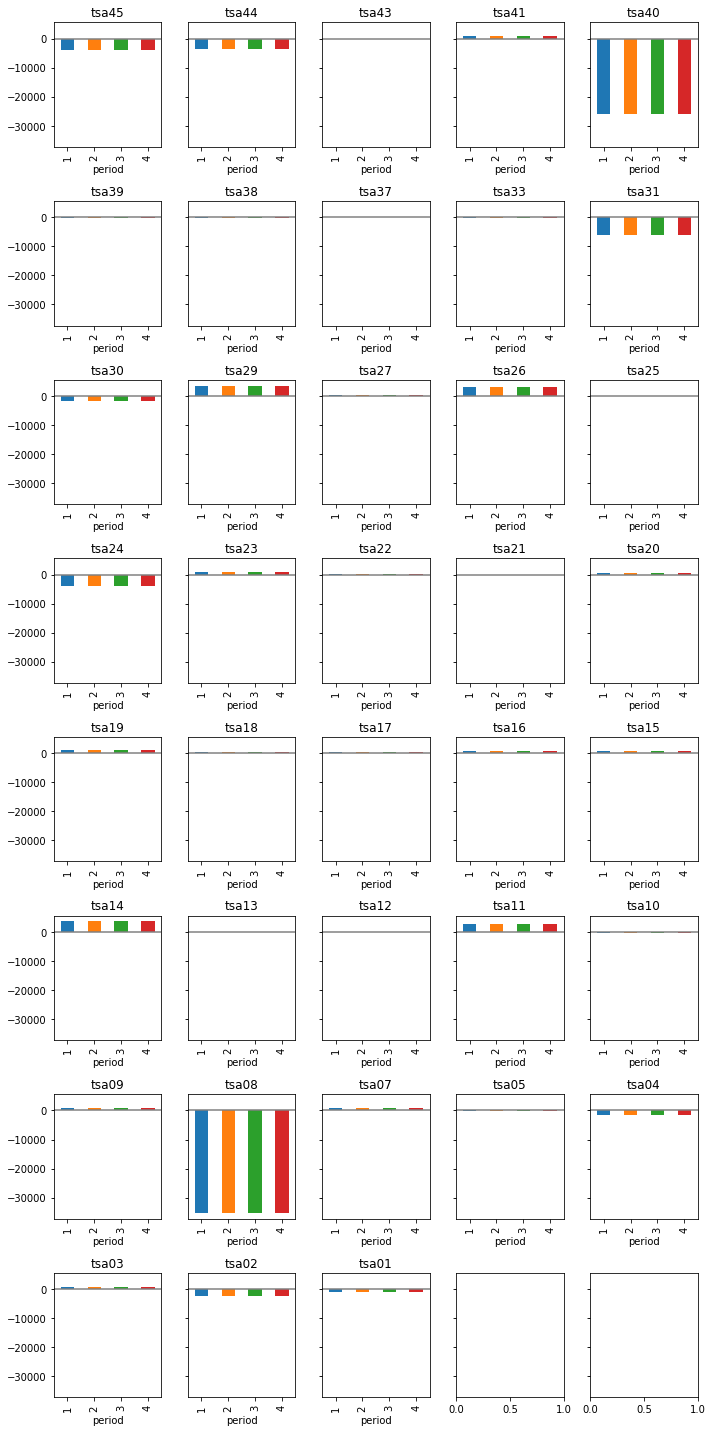

In [103]:
basenames = list(df2.index.get_level_values(level=0).unique())
fig, ax = plt.subplots(8, 5, sharey=True, figsize=(10, 20))
#plt.scatter(df2.index, df2.dvcut)
for i in range(8):
    for j in range(5):
        bn = basenames.pop() if basenames else None
        if not bn: continue
        df2.loc[bn].dabrn.plot(ax=ax[i][j], kind='bar')
        ax[i][j].axhline(color='gray')
        ax[i][j].set_title(bn)
#plt.ylim([-1.0, 10.0])
plt.tight_layout()

In [68]:
df2.rdvcut.min(), df2.rdvcut.max()

(-0.73565376521403292, 7.354734784497321)

In [83]:
df2.rdabrn.min(), df2.rdabrn.max()

(-1.0, 0.30523627075351212)

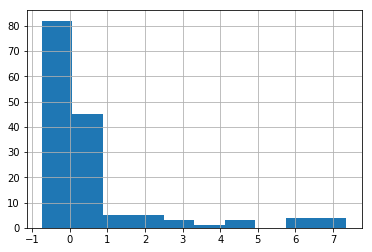

In [73]:
df2.reset_index().rdvcut.hist()

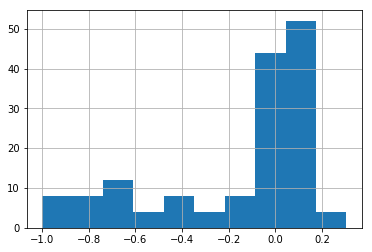

In [84]:
df2.reset_index().rdabrn.hist()

In [92]:
target_path = '../dat/targets.csv'
df_targets = pd.read_csv(target_path).set_index(['tsa', 'period'])
df_targets.head()

vcut  abrn  cflw_acut_e  cgen_vcut_e  cgen_abrn_e
tsa   period                                                      
tsa01 1       8024666  6753          0.1         0.01         0.01
      2       8024666  6753          0.1         0.01         0.01
      3       8024666  6753          0.1         0.01         0.01
      4       8024666  6753          0.1         0.01         0.01
tsa02 1       7663043   411          0.1         0.01         0.01

In [106]:
vcut_path = '../dat/out/distout_vcut.csv'
df_vcut = pd.read_csv(vcut_path).query('PERIOD < 5').set_index(['TSA', 'PERIOD'])
df_vcut.head()

SCENARIO     VCUT  ABRN
TSA   PERIOD                        
tsa01 1          base  7970835  6753
      2          base  7968418  6753
      3          base  7971327  6752
      4          base  7966712  6753
tsa02 1          base  7655838   411

In [94]:
df_vcut['vcut_target'] = df_targets['vcut']
df_vcut['vcut_diff'] = df_vcut.VCUT - df_vcut.vcut_target
df_vcut['vcut_rdiff'] = df_vcut.vcut_diff / df_vcut.vcut_target

In [107]:
df_vcut['abrn_target'] = df_targets['abrn']
df_vcut['abrn_diff'] = df_vcut.ABRN - df_vcut.abrn_target
df_vcut['abrn_rdiff'] = df_vcut.abrn_diff / df_vcut.abrn_target

In [110]:
df_vcut.abrn_diff.unique()

array([ 0, -1])

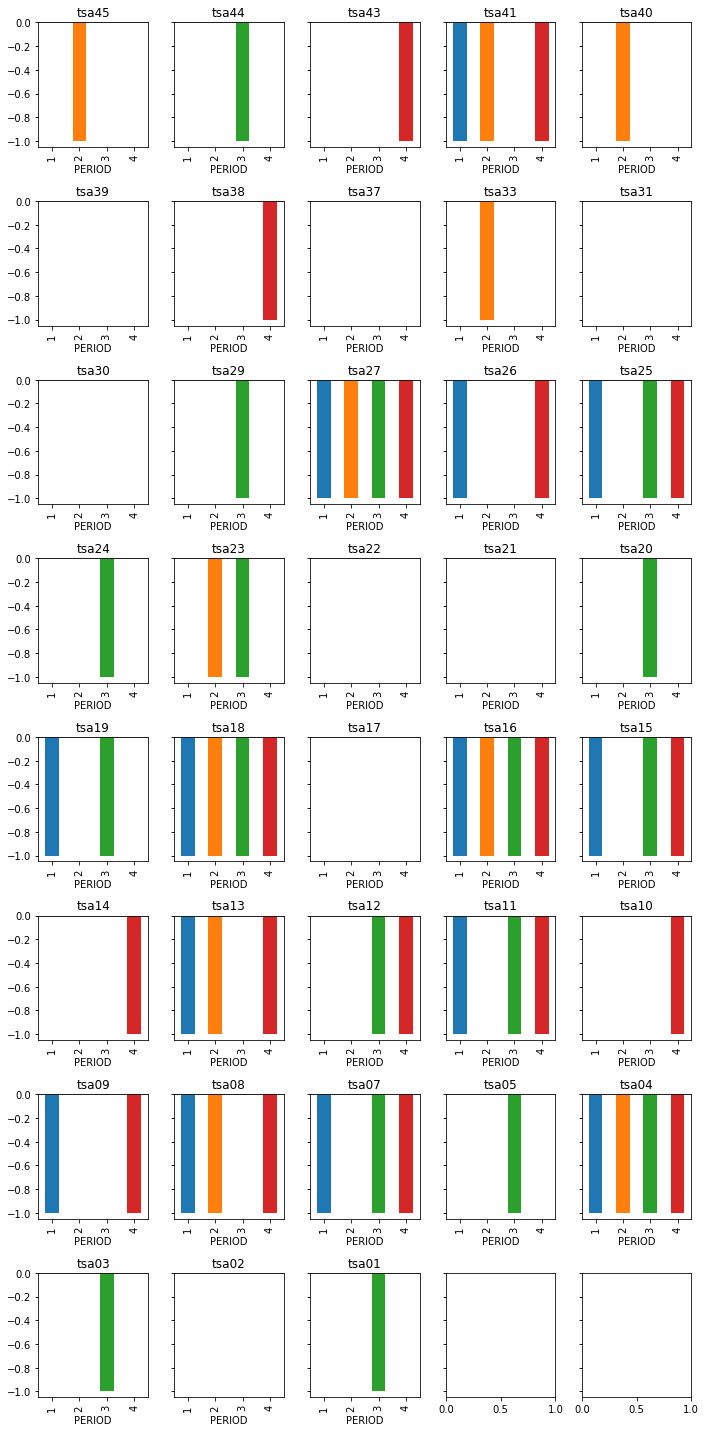

In [108]:
basenames = list(df_vcut.index.get_level_values(level=0).unique())
fig, ax = plt.subplots(8, 5, sharey=True, figsize=(10, 20))
#plt.scatter(df2.index, df2.dvcut)
for i in range(8):
    for j in range(5):
        bn = basenames.pop() if basenames else None
        if not bn: continue
        df_vcut.loc[bn].abrn_diff.plot(ax=ax[i][j], kind='bar')
        ax[i][j].axhline(color='gray')
        ax[i][j].set_title(bn)
#plt.ylim([-1.0, 10.0])
plt.tight_layout()

In [6]:
[1/2**i for i in range(1, 10)]

[0.5,
 0.25,
 0.125,
 0.0625,
 0.03125,
 0.015625,
 0.0078125,
 0.00390625,
 0.001953125]

In [7]:
(15 - 2.4) / 15

0.84

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('../dat/yld.csv')

In [3]:
df

,Yieldscode,THLB,AU,LDSPP,SPCode,Wdks,X0,X10,X20,X30,...,X260,X270,X280,X290,X300,X310,X320,X330,X340,X350
0,*Y,?,1,Aspen,AAVOL,1,0.0,0.0,1.2,5.9,...,264.3,265.5,266.7,267.9,269.0,269.5,269.5,269.5,269.4,269.4
1,*Y,?,2,Balsam fir,BFVOL,1,0.0,0.0,0.0,0.0,...,169.0,169.1,169.1,169.2,169.2,169.3,169.1,168.8,168.5,168.2
2,*Y,?,3,Subalpine fir,SFVOL,1,0.0,0.0,0.0,0.0,...,426.9,427.9,428.8,429.6,430.4,431.2,431.4,431.4,431.4,431.4
3,*Y,?,9,Hemlock,HEVOL,1,0.0,0.0,0.0,0.1,...,354.6,356.0,357.3,358.4,358.9,359.2,358.9,357.9,356.9,355.7
4,*Y,?,9,Mountain hemlock,MHVOL,1,0.0,0.0,0.0,0.1,...,354.6,356.0,357.3,358.4,358.9,359.2,358.9,357.9,356.9,355.7
5,*Y,?,14,Whitebark pine,WPVOL,1,0.0,0.0,0.0,0.0,...,152.4,153.0,153.5,154.1,154.6,155.2,155.2,155.0,154.7,154.4
6,*Y,?,15,Lodgepole pine,LPVOL,1,0.0,0.0,0.0,0.0,...,117.8,118.2,118.5,118.9,119.3,119.6,119.8,119.8,119.7,119.7
7,*Y,?,17,Spruce,SPVOL,1,0.0,0.0,0.0,0.0,...,153.7,153.6,153.4,153.3,153.2,153.2,153.1,153.1,153.0,153.0
8,*Y,?,21,Spruce,SPVOL,1,0.0,0.0,0.0,0.0,...,469.7,467.4,465.2,463.1,461.1,459.2,458.5,458.3,458.3,458.3
9,*Y,?,22,Poplar,POVOL,1,0.0,0.0,0.0,1.2,...,186.7,187.7,188.7,189.6,190.5,191.1,191.2,191.2,191.2,191.2


In [6]:
list(df['LDSPP'].unique())

['Aspen',
 'Balsam fir',
 'Subalpine fir',
 'Hemlock',
 'Mountain hemlock',
 'Whitebark pine',
 'Lodgepole pine',
 'Spruce',
 'Poplar',
 'Cottonwood',
 'Paper birch',
 'Douglas-fir',
 'Ponderosa pine',
 'Engelmann spruce',
 'Softwoods',
 'Alpine larch',
 'Black spruce',
 'White spruce',
 'Amabilis fir',
 'Redcedar',
 'Red alder',
 'Western hemlock',
 'Maple',
 'Cypress',
 'Western white pine',
 'Sitka spruce',
 'Willow',
 'Tamarack',
 'Western larch']